# 02_07 Laplace, Logistic and Gumbel

**Learning objectives**
- Meet three "cousins of the Normal": the **Laplace** (the distribution behind absolute error, L1 loss and the median), the **Logistic** (whose CDF is the sigmoid) and the **Gumbel** (the distribution of maxima).
- Derive their PDFs, means and variances, and the links to the Exponential and to Bernoulli/Categorical sampling.
- Understand why L1 loss is robust to outliers, where the **sigmoid** of logistic regression comes from, and how **return levels** (the "100-year flood") are computed.
- Solve three problems (regression with outliers, a latent-threshold buying model, yearly maximum rainfall), each by hand, in code and by simulation.

**Prerequisites:** [02_01 Uniform and Normal](02_01_uniform_normal.ipynb), [02_03 Exponential, Gamma and Erlang](02_03_exponential_gamma_erlang.ipynb), [01_05 Categorical and softmax](../../module_01_discrete/notebooks/01_05_uniform_categorical_multinomial.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Mean vs median:** the mean minimizes the *sum of squared* errors; the **median minimizes the sum of absolute errors**.
- **Exponential($\lambda$):** density $\lambda e^{-\lambda x}$ for $x\ge0$; the maximum of $n$ iid Exp(1) values grows like $\ln n$.
- **Sigmoid function:** $\sigma(z)=\dfrac1{1+e^{-z}}$, an S-shaped curve from 0 to 1; its inverse is the **logit** $\ln\frac p{1-p}$ (log-odds).
- **Softmax:** $p_j=e^{z_j}/\sum_ie^{z_i}$ turns scores into probabilities.
- **Maximum likelihood:** choose parameters that maximize $\sum\ln f(x_i)$; a Normal gives least squares.

## 3. Intuition and story

### 3.1 Laplace: the distribution of absolute errors
If errors follow a Normal, the log-density is $-\frac{(x-\mu)^2}{2\sigma^2}$, a **squared** penalty: a large error is punished enormously, so the fit is dragged toward outliers. The **Laplace** has log-density $-\frac{|x-\mu|}b$, an **absolute** penalty: big errors are punished only linearly, so outliers matter less. That is why *minimizing absolute error = maximum likelihood under Laplace noise*, and why the **median** (not the mean) is its best estimate of the center. It looks like two Exponentials glued back to back, with a sharp peak at the center.

### 3.2 Logistic: the sigmoid as a CDF
Imagine a customer buys when their latent "utility" $U=\text{(linear score)}+\varepsilon$ is above 0. If the noise $\varepsilon$ has a **Logistic** distribution, then $P(\text{buy})=P(\varepsilon>-\text{score})=\sigma(\text{score})$. The logistic CDF *is* the sigmoid, and this is the origin of **logistic regression**. The Logistic looks like a Normal with slightly heavier tails.

### 3.3 Gumbel: the distribution of the maximum
What is the biggest flood in a year, the largest of 365 daily rainfalls, the strongest wind gust? The maximum of many independent values often follows a **Gumbel** distribution (one of the three extreme-value laws). It is skewed right with an exponentially decaying upper tail. Engineers use it to compute **return levels**: "the flood expected once every 100 years".

The picture below puts the three densities next to the Normal, all with the same mean 0 and variance 1.

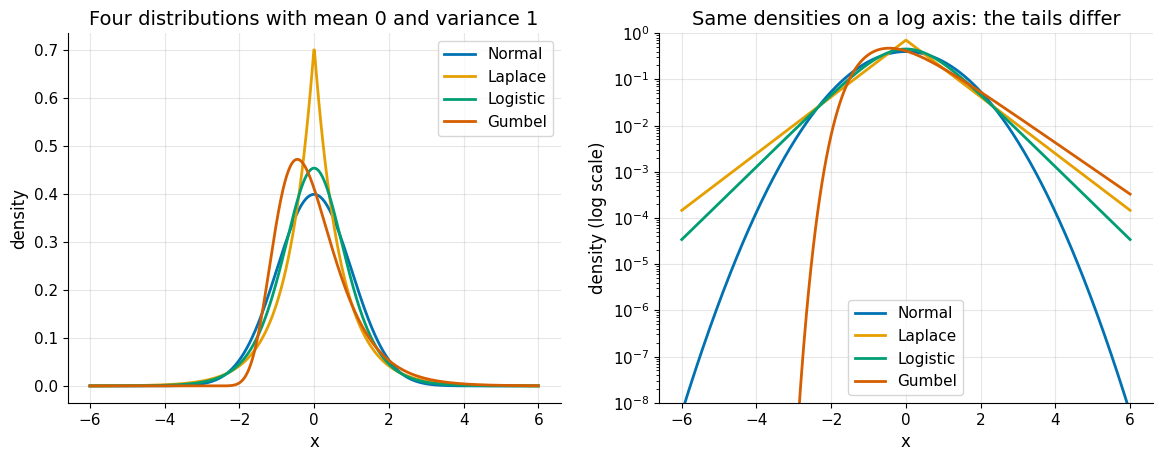

In [2]:
x_axis = np.linspace(-6, 6, 800)
laplace = stats.laplace(loc=0, scale=1 / np.sqrt(2))                       # variance 2 b^2 = 1
logistic = stats.logistic(loc=0, scale=np.sqrt(3) / np.pi)                 # variance pi^2 s^2 / 3 = 1
euler_gamma = 0.5772156649
gumbel_scale = np.sqrt(6) / np.pi                                          # variance pi^2 beta^2 / 6 = 1
gumbel = stats.gumbel_r(loc=-euler_gamma * gumbel_scale, scale=gumbel_scale)   # shifted to mean 0
normal = stats.norm(0, 1)

fig, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(14, 4.8))
for name, dist, color in [("Normal", normal, COLORS[0]), ("Laplace", laplace, COLORS[1]), ("Logistic", logistic, COLORS[2]), ("Gumbel", gumbel, COLORS[3])]:
    ax_lin.plot(x_axis, dist.pdf(x_axis), color=color, linewidth=2, label=name)
    ax_log.semilogy(x_axis, dist.pdf(x_axis), color=color, linewidth=2, label=name)
ax_lin.set_title("Four distributions with mean 0 and variance 1")
ax_lin.set_xlabel("x")
ax_lin.set_ylabel("density")
ax_lin.legend()
ax_log.set_ylim(1e-8, 1)
ax_log.set_title("Same densities on a log axis: the tails differ")
ax_log.set_xlabel("x")
ax_log.set_ylabel("density (log scale)")
ax_log.legend()
plt.show()

**In plain words.** The Laplace has a sharper peak and fatter tails than the Normal (a tent on the log axis, where the Normal is a parabola). The Logistic is like a Normal with a little more tail. The Gumbel is lopsided: a long right tail, a short left one.

## 4. Formal definition

**Laplace($\mu,b$):** support $\mathbb R$; location $\mu$, scale $b>0$.
$$f(x)=\frac1{2b}e^{-|x-\mu|/b},\qquad F(x)=\begin{cases}\tfrac12e^{(x-\mu)/b}&x<\mu\\[2pt]1-\tfrac12e^{-(x-\mu)/b}&x\ge\mu.\end{cases}$$

**Logistic($\mu,s$):** support $\mathbb R$; location $\mu$, scale $s>0$.
$$F(x)=\frac1{1+e^{-(x-\mu)/s}}=\sigma\Big(\frac{x-\mu}s\Big),\qquad f(x)=\frac{F(x)(1-F(x))}s=\frac{e^{-(x-\mu)/s}}{s\,(1+e^{-(x-\mu)/s})^2}.$$

**Gumbel (maximum type)($\mu,\beta$):** support $\mathbb R$; location $\mu$ (the mode), scale $\beta>0$.
$$F(x)=\exp\!\Big(-e^{-(x-\mu)/\beta}\Big),\qquad f(x)=\frac1\beta\,e^{-z-e^{-z}},\quad z=\frac{x-\mu}\beta.$$

**`scipy`:** `stats.laplace(loc, scale)`, `stats.logistic(loc, scale)`, `stats.gumbel_r(loc, scale)` (`gumbel_l` is the minimum version).

## 5. Derivations

### 5.1 Laplace: normalization, mean and variance
By symmetry about $\mu$, $\int f=2\int_\mu^\infty\frac1{2b}e^{-(x-\mu)/b}dx=\big[-e^{-(x-\mu)/b}\big]_\mu^\infty=1$. The mean is $\mu$ (symmetric). For the variance put $u=|x-\mu|$:
$$\mathrm{Var}(X)=\int_0^\infty u^2\frac1be^{-u/b}du=\frac{2b^3}{b}=2b^2.$$
(The $u^2$-moment of an Exponential with mean $b$ is $2b^2$.) So $\text{SD}=b\sqrt2$.

### 5.2 Laplace: MGF and kurtosis
$M(t)=\dfrac{e^{\mu t}}{1-b^2t^2}$ for $|t|<1/b$. The fourth central moment is $24b^4$, so kurtosis is $24b^4/(2b^2)^2=6$ and **excess kurtosis is 3**: much heavier tails than the Normal (0).

### 5.3 Laplace as a difference of exponentials
If $E_1,E_2$ are independent Exponential with mean $b$ then $E_1-E_2\sim\text{Laplace}(0,b)$. (The MGF of the difference is $\frac1{1-bt}\cdot\frac1{1+bt}=\frac1{1-b^2t^2}$.)

### 5.4 Laplace and L1 loss
For data $x_1..x_n$ the log-likelihood is $-n\ln(2b)-\frac1b\sum|x_i-\mu|$. Maximizing over $\mu$ means **minimizing $\sum|x_i-\mu|$**, solved by the **median**. Then $\hat b=\frac1n\sum|x_i-\text{median}|$ (the mean absolute deviation). A Laplace *prior* on regression weights gives the L1 penalty (LASSO), which pushes weights to exactly 0 (sparsity).

### 5.5 Logistic: from the sigmoid
Differentiating $F=(1+e^{-z})^{-1}$ gives $F'=e^{-z}(1+e^{-z})^{-2}=F(1-F)$: the density is the CDF times its complement. The **quantile function is the logit**: $x_p=\mu+s\ln\frac p{1-p}$. The variance is $\pi^2s^2/3$ (from the integral $\int z^2\frac{e^{-z}}{(1+e^{-z})^2}dz=\pi^2/3$), and the excess kurtosis is $1.2$.

### 5.6 Logistic regression from a latent variable
Let the latent utility be $U=\beta_0+\beta_1x+\varepsilon$ with $\varepsilon\sim\text{Logistic}(0,1)$, and $Y=1$ if $U>0$. Then
$$P(Y=1\mid x)=P(\varepsilon>-(\beta_0+\beta_1x))=1-F(-\eta)=F(\eta)=\sigma(\eta),\qquad\eta=\beta_0+\beta_1x.$$
The log-odds are linear in $x$: $\ln\frac{p}{1-p}=\eta$, and each unit of $x$ multiplies the odds by $e^{\beta_1}$.

### 5.7 Gumbel as the limit of maxima
Let $M_n=\max(E_1,\dots,E_n)$ for iid Exponential(1). Then $P(M_n\le x)=(1-e^{-x})^n$. Shift by $\ln n$: $P(M_n-\ln n\le z)=\big(1-\frac{e^{-z}}n\big)^n\to\exp(-e^{-z})$. So $M_n\approx\text{Gumbel}(\mu=\ln n,\beta=1)$. This is why Gumbel describes maxima of light-tailed variables (Exponential, Normal, Gamma).

### 5.8 Gumbel moments, quantiles and return levels
Mean $=\mu+\gamma\beta$ with $\gamma=0.5772$ (Euler's constant); variance $=\pi^2\beta^2/6$; skewness $1.1396$ (fixed); excess kurtosis $2.4$; mode $\mu$; median $\mu-\beta\ln\ln2$. Inverting the CDF:
$$x_p=\mu-\beta\ln\!\big(-\ln p\big).$$
The **$T$-year return level** is the value exceeded with probability $1/T$ per year: $x_T=\mu-\beta\ln\!\big(-\ln(1-1/T)\big)$.

### 5.9 The Gumbel-max trick
Let $G_1,\dots,G_k$ be iid standard Gumbel and $z_j$ scores. Then $\arg\max_j(z_j+G_j)$ is a **Categorical** draw with probabilities $\text{softmax}(z)$. Reason: $P(\text{index }j\text{ wins})=\int f_{G}(g)\prod_{i\ne j}F_G(g+z_j-z_i)\,dg=\dfrac{e^{z_j}}{\sum_ie^{z_i}}$. It is used to sample categories and in the Gumbel-softmax relaxation (ML section).

## 6. Properties and relationships

- **Laplace** = difference of two iid Exponentials = a Normal with an Exponentially distributed variance (scale mixture).
- **Logistic** = difference of two iid Gumbels; its CDF is the sigmoid, its quantile function the logit.
- **Gumbel** is the limit law for maxima of Exponential-tailed variables; a heavy tail (Pareto) gives the Fréchet law instead, a bounded variable the (reverse) Weibull.
- **Minimum vs maximum:** `gumbel_l` is the mirror image `-X`.
- **Robustness:** Laplace and Logistic have heavier tails than the Normal, and the Laplace median estimator ignores outliers.
- **Parameters are not mean and SD:** use the formulas above (e.g. Laplace SD $=b\sqrt2$).

## 7. 2D visuals

### 7.1 Laplace PDF, CDF and effect of b
The tent-shaped PDF (a sharp peak) and its CDF. A larger b spreads the distribution but keeps the sharp peak.

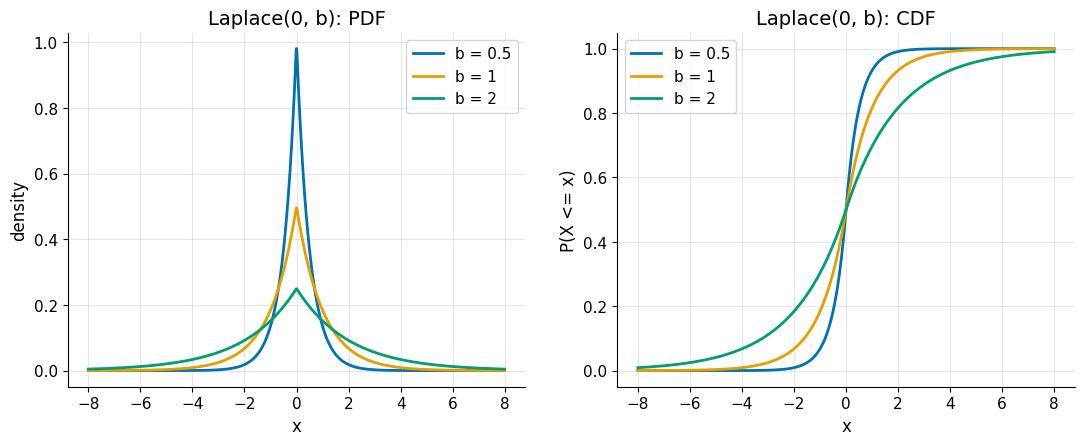

In [3]:
x_axis = np.linspace(-8, 8, 800)
fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=(13, 4.6))
for b_value, color in zip([0.5, 1, 2], COLORS):
    d = stats.laplace(0, b_value)
    ax_pdf.plot(x_axis, d.pdf(x_axis), color=color, linewidth=2, label=f"b = {b_value}")
    ax_cdf.plot(x_axis, d.cdf(x_axis), color=color, linewidth=2, label=f"b = {b_value}")
ax_pdf.set_title("Laplace(0, b): PDF")
ax_pdf.set_xlabel("x")
ax_pdf.set_ylabel("density")
ax_pdf.legend()
ax_cdf.set_title("Laplace(0, b): CDF")
ax_cdf.set_xlabel("x")
ax_cdf.set_ylabel("P(X <= x)")
ax_cdf.legend()
plt.show()

### 7.2 Laplace log-density: a tent versus a parabola
On the log scale the Laplace is a **tent** (absolute value) while the Normal is a **parabola** (squared). The tent penalizes far-away points linearly rather than quadratically: this is the picture of robustness.

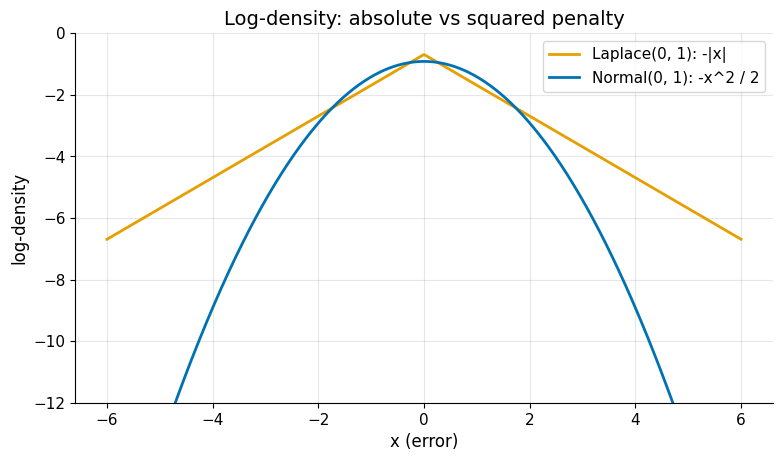

In [4]:
x_axis = np.linspace(-6, 6, 600)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x_axis, stats.laplace(0, 1).logpdf(x_axis), color=COLORS[1], linewidth=2, label="Laplace(0, 1): -|x|")
ax.plot(x_axis, stats.norm(0, 1).logpdf(x_axis), color=COLORS[0], linewidth=2, label="Normal(0, 1): -x^2 / 2")
ax.set_ylim(-12, 0)
ax.set_title("Log-density: absolute vs squared penalty")
ax.set_xlabel("x (error)")
ax.set_ylabel("log-density")
ax.legend()
plt.show()

### 7.3 Logistic: the sigmoid CDF and the scale s
The CDF is a sigmoid; the scale s controls how fast it rises (small s is a sharp switch). The Logistic density is slightly more peaked and heavier-tailed than the Normal.

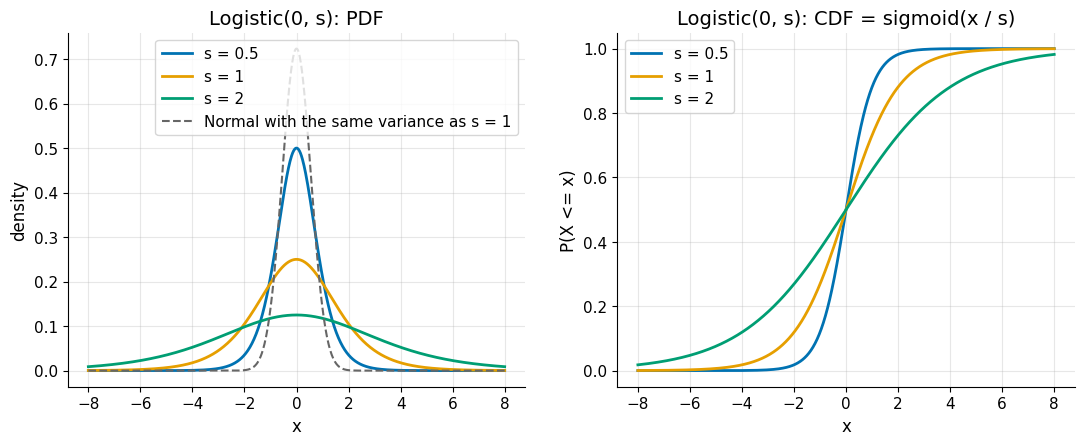

In [5]:
x_axis = np.linspace(-8, 8, 800)
fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=(13, 4.6))
for s_value, color in zip([0.5, 1, 2], COLORS):
    d = stats.logistic(0, s_value)
    ax_pdf.plot(x_axis, d.pdf(x_axis), color=color, linewidth=2, label=f"s = {s_value}")
    ax_cdf.plot(x_axis, d.cdf(x_axis), color=color, linewidth=2, label=f"s = {s_value}")
ax_pdf.plot(x_axis, stats.norm(0, np.sqrt(3) / np.pi).pdf(x_axis), "--", color=NEUTRAL, label="Normal with the same variance as s = 1")
ax_pdf.set_title("Logistic(0, s): PDF")
ax_pdf.set_xlabel("x")
ax_pdf.set_ylabel("density")
ax_pdf.legend()
ax_cdf.set_title("Logistic(0, s): CDF = sigmoid(x / s)")
ax_cdf.set_xlabel("x")
ax_cdf.set_ylabel("P(X <= x)")
ax_cdf.legend()
plt.show()

### 7.4 Gumbel PDF, effect of mu and beta
The Gumbel peaks at mu, has a long right tail, and a shorter left tail. Beta stretches it; mu shifts it.

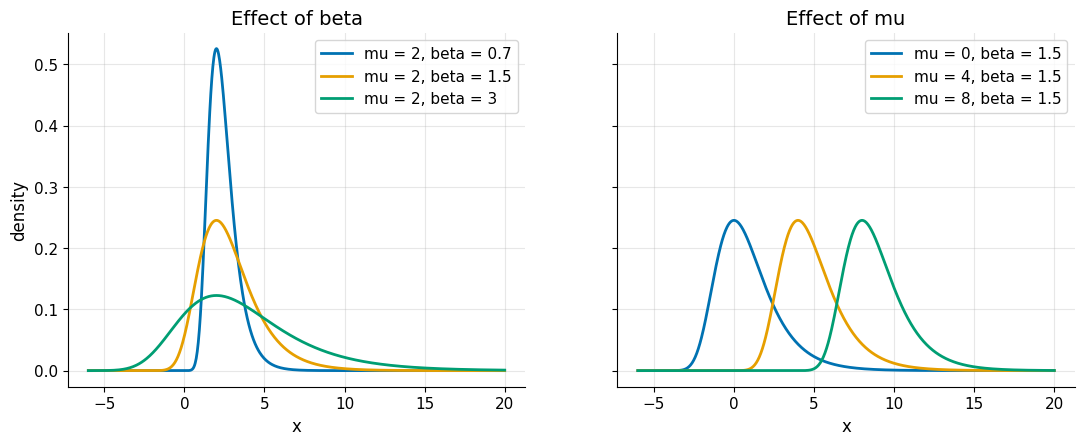

In [6]:
x_axis = np.linspace(-6, 20, 800)
fig, (ax_beta, ax_mu) = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for beta_value, color in zip([0.7, 1.5, 3], COLORS):
    ax_beta.plot(x_axis, stats.gumbel_r(2, beta_value).pdf(x_axis), color=color, linewidth=2, label=f"mu = 2, beta = {beta_value}")
for mu_value, color in zip([0, 4, 8], COLORS):
    ax_mu.plot(x_axis, stats.gumbel_r(mu_value, 1.5).pdf(x_axis), color=color, linewidth=2, label=f"mu = {mu_value}, beta = 1.5")
ax_beta.set_title("Effect of beta")
ax_beta.set_xlabel("x")
ax_beta.set_ylabel("density")
ax_beta.legend()
ax_mu.set_title("Effect of mu")
ax_mu.set_xlabel("x")
ax_mu.legend()
plt.show()

### 7.5 The limit behind the Gumbel: maxima of exponentials
The maximum of n Exponential(1) values, shifted by ln n, converges to a standard Gumbel as n grows.

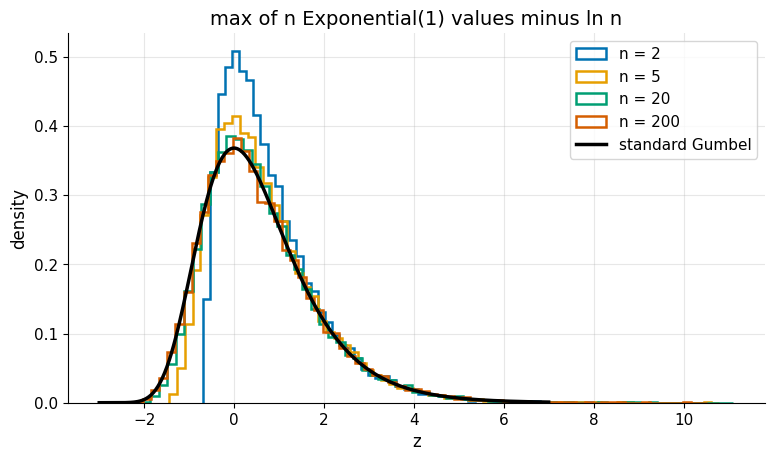

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.8))
z_axis = np.linspace(-3, 7, 400)
for n, color in zip([2, 5, 20, 200], COLORS):
    maxima = rng.exponential(1, size=(30_000, n)).max(axis=1) - np.log(n)
    ax.hist(maxima, bins=70, density=True, histtype="step", color=color, linewidth=1.8, label=f"n = {n}")
ax.plot(z_axis, stats.gumbel_r(0, 1).pdf(z_axis), color="black", linewidth=2.5, label="standard Gumbel")
ax.set_title("max of n Exponential(1) values minus ln n")
ax.set_xlabel("z")
ax.set_ylabel("density")
ax.legend()
plt.show()

## 8. 3D visuals

### 8.1 Static: Laplace PDF over (x, b)
A ridge of sharp peaks that flattens and widens as b grows.

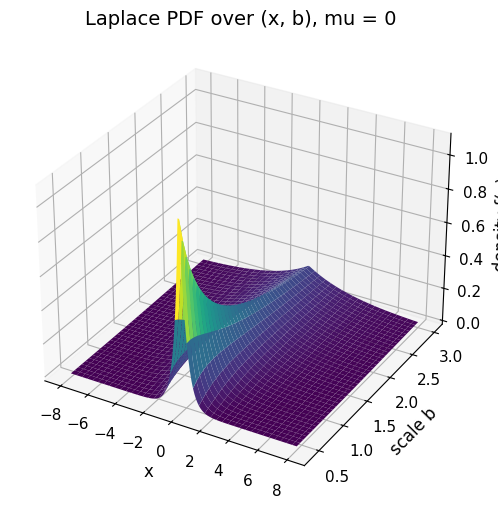

In [8]:
x_values = np.linspace(-8, 8, 160)
b_values = np.linspace(0.4, 3, 40)
X, B = np.meshgrid(x_values, b_values)
Z = np.exp(-np.abs(X) / B) / (2 * B)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, B, Z, cmap="viridis", edgecolor="none")
ax.set_title("Laplace PDF over (x, b), mu = 0")
ax.set_xlabel("x")
ax.set_ylabel("scale b")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: Logistic CDF over (x, s)
The sigmoid becomes steeper as s shrinks; at s near 0 it is a step function.

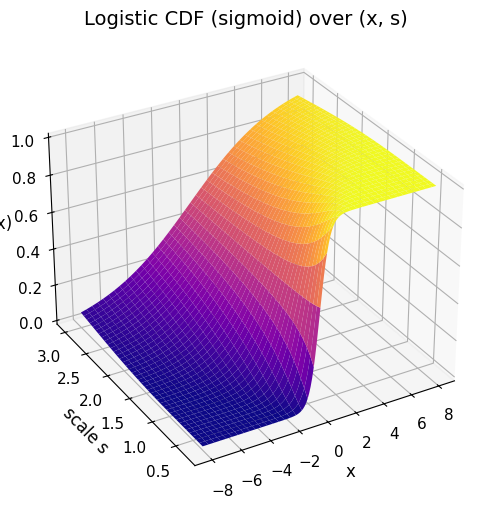

In [9]:
s_values = np.linspace(0.3, 3, 40)
X2, S2 = np.meshgrid(x_values, s_values)
Z2 = stats.logistic.cdf(X2, loc=0, scale=S2)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X2, S2, Z2, cmap="plasma", edgecolor="none")
ax.set_title("Logistic CDF (sigmoid) over (x, s)")
ax.set_xlabel("x")
ax.set_ylabel("scale s")
ax.set_zlabel("F(x)")
ax.view_init(elev=30, azim=-120)
plt.show()

### 8.3 Static: Gumbel PDF over (x, beta)
The skewed peak at mu = 0 widens and drops as beta grows.

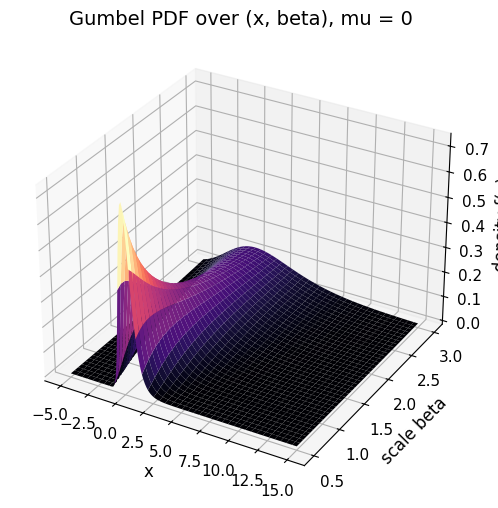

In [10]:
beta_values = np.linspace(0.5, 3, 40)
X3, B3 = np.meshgrid(np.linspace(-5, 15, 160), beta_values)
Z3 = stats.gumbel_r.pdf(X3, loc=0, scale=B3)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X3, B3, Z3, cmap="magma", edgecolor="none")
ax.set_title("Gumbel PDF over (x, beta), mu = 0")
ax.set_xlabel("x")
ax.set_ylabel("scale beta")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.4 Interactive Plotly version
The Gumbel surface of 8.3; drag to rotate.

In [11]:
fig = go.Figure(go.Surface(x=np.linspace(-5, 15, 160), y=beta_values, z=Z3, colorscale="Magma"))
fig.update_layout(title="Gumbel PDF over (x, beta), mu = 0", width=750, height=550,
                  scene=dict(xaxis_title="x", yaxis_title="scale beta", zaxis_title="density f(x)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histograms against the PDFs
50,000 draws from each distribution.

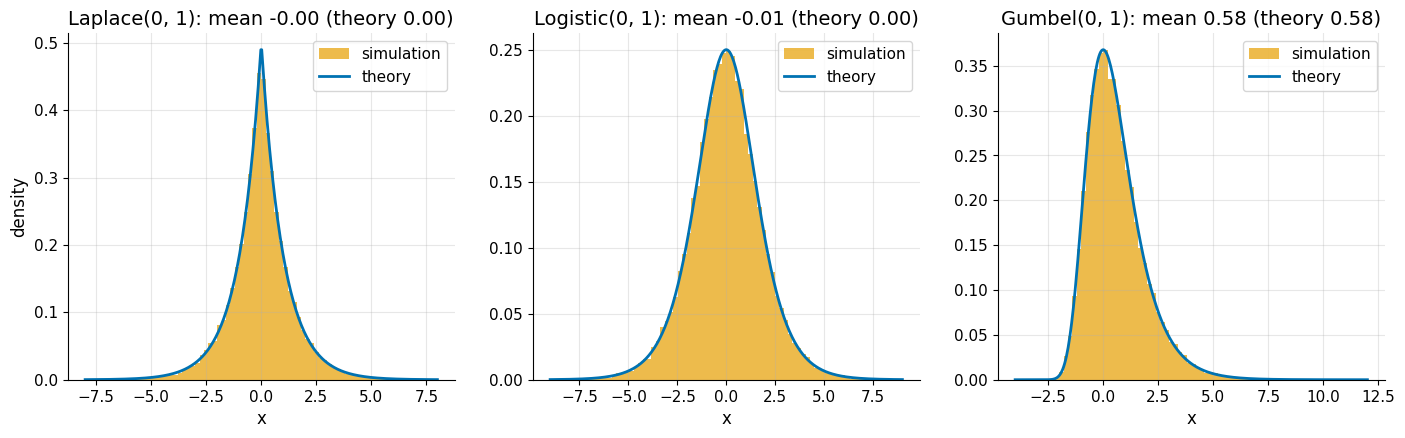

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
cases = [("Laplace(0, 1)", rng.laplace(0, 1, 50_000), stats.laplace(0, 1), np.linspace(-8, 8, 400)),
         ("Logistic(0, 1)", rng.logistic(0, 1, 50_000), stats.logistic(0, 1), np.linspace(-9, 9, 400)),
         ("Gumbel(0, 1)", rng.gumbel(0, 1, 50_000), stats.gumbel_r(0, 1), np.linspace(-4, 12, 400))]
for ax, (name, draws, dist, grid) in zip(axes, cases):
    ax.hist(draws, bins=80, range=(grid[0], grid[-1]), density=True, color=SIM, alpha=0.7, label="simulation")
    ax.plot(grid, dist.pdf(grid), color=MAIN, linewidth=2, label="theory")
    ax.set_title(f"{name}: mean {draws.mean():.2f} (theory {dist.mean():.2f})")
    ax.set_xlabel("x")
    ax.legend()
axes[0].set_ylabel("density")
plt.show()

### 9.2 Running means converge
All three have finite means, so the running means settle (Laplace to 0, Logistic to 0, Gumbel to Euler's constant 0.577).

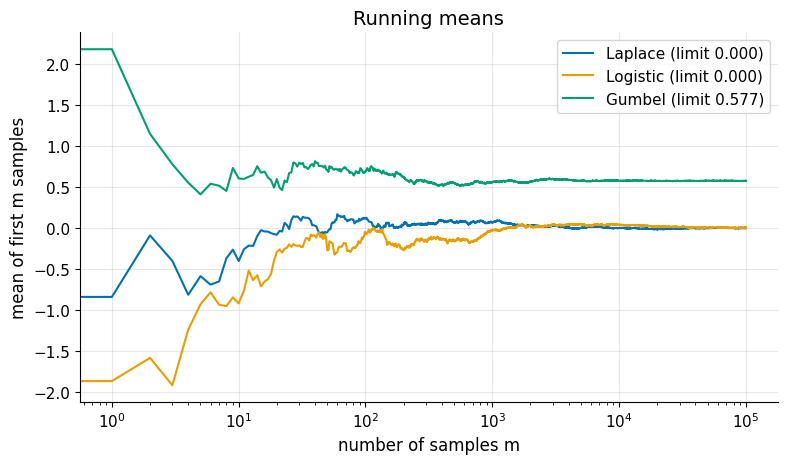

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for name, draws, target, color in [("Laplace", rng.laplace(0, 1, 100_000), 0.0, COLORS[0]), ("Logistic", rng.logistic(0, 1, 100_000), 0.0, COLORS[1]), ("Gumbel", rng.gumbel(0, 1, 100_000), euler_gamma, COLORS[2])]:
    ax.plot(np.cumsum(draws) / np.arange(1, len(draws) + 1), color=color, label=f"{name} (limit {target:.3f})")
ax.set_xscale("log")
ax.set_title("Running means")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.legend()
plt.show()

### 9.3 Laplace as a difference of two Exponentials
The difference of two independent Exponential(mean b = 1) waits is Laplace(0, 1).

In [14]:
difference = rng.exponential(1, 50_000) - rng.exponential(1, 50_000)
print("KS test against Laplace(0, 1): p-value =", round(stats.kstest(difference, stats.laplace(0, 1).cdf).pvalue, 3))
print(f"sample variance {difference.var():.3f} (theory 2 b^2 = 2)")

KS test against Laplace(0, 1): p-value = 0.423
sample variance 2.003 (theory 2 b^2 = 2)


### 9.4 The Gumbel-max trick samples a Categorical
We add Gumbel noise to scores and take the arg-max. The winning frequencies match softmax(scores).

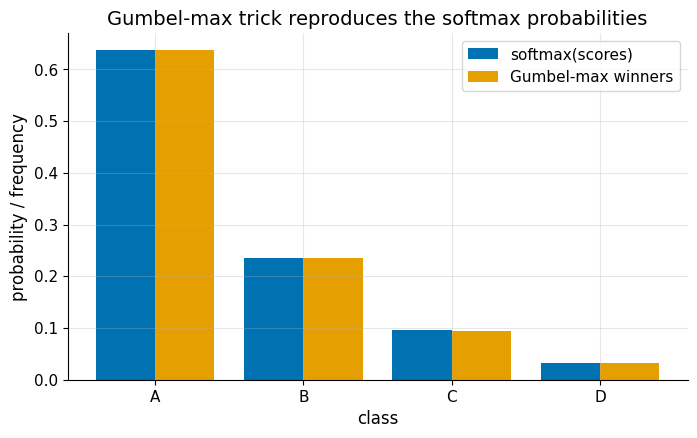

In [15]:
scores = np.array([2.0, 1.0, 0.1, -1.0])
softmax_probs = np.exp(scores) / np.exp(scores).sum()

noise = rng.gumbel(size=(200_000, 4))
winners = np.argmax(scores + noise, axis=1)
frequencies = np.bincount(winners, minlength=4) / len(winners)

positions = np.arange(4)
fig, ax = plt.subplots()
ax.bar(positions - 0.2, softmax_probs, width=0.4, color=MAIN, label="softmax(scores)")
ax.bar(positions + 0.2, frequencies, width=0.4, color=SIM, label="Gumbel-max winners")
ax.set_xticks(positions)
ax.set_xticklabels(["A", "B", "C", "D"])
ax.set_title("Gumbel-max trick reproduces the softmax probabilities")
ax.set_xlabel("class")
ax.set_ylabel("probability / frequency")
ax.legend()
plt.show()
assert np.allclose(softmax_probs, frequencies, atol=0.005)

## 10. `scipy.stats` cheat sheet

In [16]:
lap = stats.laplace(loc=0, scale=1)
print("laplace pdf(0), cdf(2), sf(2):", round(lap.pdf(0), 4), round(lap.cdf(2), 4), round(lap.sf(2), 4), "(sf(2) = exp(-2) / 2)")
print("laplace var, std       :", lap.var(), round(lap.std(), 4))
print("laplace ppf(0.975)     :", round(lap.ppf(0.975), 4))

lg = stats.logistic(loc=0, scale=1)
print("logistic cdf(1.5)      :", round(lg.cdf(1.5), 4), " sigmoid(1.5) =", round(1 / (1 + np.exp(-1.5)), 4))
print("logistic ppf(0.8)      :", round(lg.ppf(0.8), 4), " logit(0.8) =", round(np.log(0.8 / 0.2), 4))
print("logistic var           :", round(lg.var(), 4), "= pi^2 / 3 =", round(np.pi**2 / 3, 4))

gb = stats.gumbel_r(loc=80, scale=20)
print("gumbel mean, std       :", round(gb.mean(), 3), round(gb.std(), 3), "(mean = mu + 0.5772 beta =", round(80 + euler_gamma * 20, 3), ")")
print("gumbel sf(150)         :", round(gb.sf(150), 5))
print("gumbel ppf(0.99)       :", round(gb.ppf(0.99), 2), "(100-year return level)")
print("gumbel stats mvsk      :", np.round(gb.stats(moments="mvsk"), 3))

laplace pdf(0), cdf(2), sf(2): 0.5 0.9323 0.0677 (sf(2) = exp(-2) / 2)
laplace var, std       : 2.0 1.4142
laplace ppf(0.975)     : 2.9957
logistic cdf(1.5)      : 0.8176  sigmoid(1.5) = 0.8176
logistic ppf(0.8)      : 1.3863  logit(0.8) = 1.3863
logistic var           : 3.2899 = pi^2 / 3 = 3.2899
gumbel mean, std       : 91.544 25.651 (mean = mu + 0.5772 beta = 91.544 )
gumbel sf(150)         : 0.02975
gumbel ppf(0.99)       : 172.0 (100-year return level)
gumbel stats mvsk      : [ 91.544 657.974   1.14    2.4  ]


**Fitting:** `fit` returns (loc, scale) by maximum likelihood. For the Laplace the MLE is the median and the mean absolute deviation.

In [17]:
data = stats.laplace(5, 2).rvs(size=4000, random_state=3)
loc_hat, scale_hat = stats.laplace.fit(data)
print(f"Laplace(5, 2): fit loc = {loc_hat:.3f} (median {np.median(data):.3f}), scale = {scale_hat:.3f} (mean abs deviation {np.mean(np.abs(data - np.median(data))):.3f})")
print("Logistic fit:", np.round(stats.logistic.fit(stats.logistic(1, 0.5).rvs(4000, random_state=4)), 3), "(truth 1, 0.5)")
print("Gumbel fit  :", np.round(stats.gumbel_r.fit(stats.gumbel_r(80, 20).rvs(4000, random_state=5)), 2), "(truth 80, 20)")

Laplace(5, 2): fit loc = 4.984 (median 4.984), scale = 1.972 (mean abs deviation 1.972)
Logistic fit: [1.007 0.506] (truth 1, 0.5)
Gumbel fit  : [80.01 19.75] (truth 80, 20)


## 11. Real-world worked examples

---
### Example 1 (main): regression errors and outliers (L1 vs L2)

**Scenario (illustrative numbers).** A sensor's measurement error is modelled as **Laplace(0, $b=1$ unit)**. The occasional glitch is large, which a Normal handles badly. We compare the Laplace with the Normal of the **same variance** ($\sigma=\sqrt2$), then show how the *mean* and the *median* behave when a few readings are corrupted, and how a least-squares (L2) line and a least-absolute-deviation (L1) line react to outliers.

**Questions**
1. What is the probability that an error exceeds **2 units** in absolute value, under the Laplace and under the same-variance Normal? And exceeding 5 units?
2. 20 readings of a true value 10 include 3 outliers. Which is better, the **mean or the median**?
3. A straight-line fit with 3 corrupted points: how different are the **L2 and L1 slopes**?

### 11.1 By hand
**Q1.** Laplace tail: $P(|X|>t)=e^{-t/b}$. So $P(|X|>2)=e^{-2}=0.1353$ and $P(|X|>5)=e^{-5}=0.00674$. The same-variance Normal has $\sigma=\sqrt2=1.4142$: $P(|X|>2)=2(1-\Phi(1.414))=2(0.0787)=0.1573$ and $P(|X|>5)=2(1-\Phi(3.536))=0.000406$. At 5 units the Laplace is **about 17 times** more likely than the Normal; at 2 units the Normal is slightly *more* likely (the Laplace has more mass in the center *and* far tail).

**Q2.** Take the readings $9.8,\,10.1,\,9.9,\,10.2,\,10.0,\dots$ and add outliers 25, 30, 28. The mean is pulled up by the outliers; the median (the middle value) barely moves, since it ignores the size of the extremes.

**Q3.** Least squares minimizes $\sum e_i^2$ (a parabola penalty), least absolute deviations minimizes $\sum|e_i|$ (a tent): the outliers' pull grows with the square vs linearly. We solve both numerically below.

In [18]:
import math

b_scale = 1.0
sigma_same_variance = math.sqrt(2) * b_scale

def standard_normal_cdf(z):
    return 0.5 * (1 + math.erf(z / math.sqrt(2)))

laplace_over_2_hand = math.exp(-2 / b_scale)
laplace_over_5_hand = math.exp(-5 / b_scale)
normal_over_2_hand = 2 * (1 - standard_normal_cdf(2 / sigma_same_variance))
normal_over_5_hand = 2 * (1 - standard_normal_cdf(5 / sigma_same_variance))
print(f"Laplace: P(|X|>2) = {laplace_over_2_hand:.4f}, P(|X|>5) = {laplace_over_5_hand:.5f}")
print(f"Normal (same variance): P(|X|>2) = {normal_over_2_hand:.4f}, P(|X|>5) = {normal_over_5_hand:.6f}")
print(f"ratio at 5 units: {laplace_over_5_hand / normal_over_5_hand:.1f}")

Laplace: P(|X|>2) = 0.1353, P(|X|>5) = 0.00674
Normal (same variance): P(|X|>2) = 0.1573, P(|X|>5) = 0.000407
ratio at 5 units: 16.6


### 11.2 In code with `scipy`, and the asserts

In [19]:
error_laplace = stats.laplace(0, b_scale)
error_normal = stats.norm(0, sigma_same_variance)

assert np.isclose(laplace_over_2_hand, 2 * error_laplace.sf(2))
assert np.isclose(laplace_over_5_hand, 2 * error_laplace.sf(5))
assert np.isclose(normal_over_2_hand, 2 * error_normal.sf(2))
assert np.isclose(normal_over_5_hand, 2 * error_normal.sf(5))
assert np.isclose(error_laplace.var(), error_normal.var())

# Q2: mean vs median with outliers
readings = np.array([9.8, 10.1, 9.9, 10.2, 10.0, 10.3, 9.7, 10.1, 9.9, 10.0, 10.2, 9.8, 10.1, 9.9, 10.0, 10.2, 9.8, 25.0, 30.0, 28.0])
print(f"true value 10: mean = {readings.mean():.2f}, median = {np.median(readings):.2f}")

# Q3: straight-line fit by least squares (L2) and least absolute deviations (L1)
from scipy import optimize
x_data = np.linspace(0, 10, 30)
y_data = 2 * x_data + 1 + rng.laplace(0, 0.5, size=30)
y_data[[24, 26, 28]] += [25, 30, 28]                                  # three corrupted points
slope_l2, intercept_l2 = np.polyfit(x_data, y_data, deg=1)
l1_loss = lambda params: np.sum(np.abs(y_data - (params[0] * x_data + params[1])))
slope_l1, intercept_l1 = optimize.minimize(l1_loss, x0=[slope_l2, intercept_l2], method="Nelder-Mead").x
print(f"true line y = 2x + 1; L2 fit: y = {slope_l2:.2f}x + {intercept_l2:.2f}; L1 fit: y = {slope_l1:.2f}x + {intercept_l1:.2f}")
assert abs(slope_l1 - 2) < abs(slope_l2 - 2)
assert abs(np.median(readings) - 10) < abs(readings.mean() - 10)

true value 10: mean = 12.65, median = 10.05
true line y = 2x + 1; L2 fit: y = 3.19x + -2.37; L1 fit: y = 1.96x + 1.07


### 11.3 Verify by simulation
Simulate 2 million errors from each model and check the tail probabilities. Then repeat the mean-versus-median comparison 5,000 times to see which estimator is more accurate when 15 % of readings are corrupted.

In [20]:
laplace_errors = rng.laplace(0, b_scale, size=2_000_000)
normal_errors = rng.normal(0, sigma_same_variance, size=2_000_000)
print(f"Laplace: P(|X|>2) exact {2 * error_laplace.sf(2):.4f} simulated {np.mean(np.abs(laplace_errors) > 2):.4f}; P(|X|>5) exact {2 * error_laplace.sf(5):.5f} simulated {np.mean(np.abs(laplace_errors) > 5):.5f}")
print(f"Normal:  P(|X|>2) exact {2 * error_normal.sf(2):.4f} simulated {np.mean(np.abs(normal_errors) > 2):.4f}; P(|X|>5) exact {2 * error_normal.sf(5):.6f} simulated {np.mean(np.abs(normal_errors) > 5):.6f}")
assert abs(np.mean(np.abs(laplace_errors) > 2) - 2 * error_laplace.sf(2)) < 0.001

n_readings, n_trials = 40, 5000
errors_of_mean, errors_of_median = [], []
for _ in range(n_trials):
    clean = rng.normal(10, 0.2, size=n_readings)
    corrupted = rng.uniform(size=n_readings) < 0.15
    clean[corrupted] += rng.uniform(10, 25, size=corrupted.sum())
    errors_of_mean.append(clean.mean() - 10)
    errors_of_median.append(np.median(clean) - 10)
print(f"with 15 % corrupted readings: RMS error of the mean = {np.sqrt(np.mean(np.square(errors_of_mean))):.2f}, of the median = {np.sqrt(np.mean(np.square(errors_of_median))):.2f}")

Laplace: P(|X|>2) exact 0.1353 simulated 0.1354; P(|X|>5) exact 0.00674 simulated 0.00675

Normal:  P(|X|>2) exact 0.1573 simulated 0.1573; P(|X|>5) exact 0.000407 simulated 0.000414


with 15 % corrupted readings: RMS error of the mean = 2.80, of the median = 0.06


### 11.4 Plots

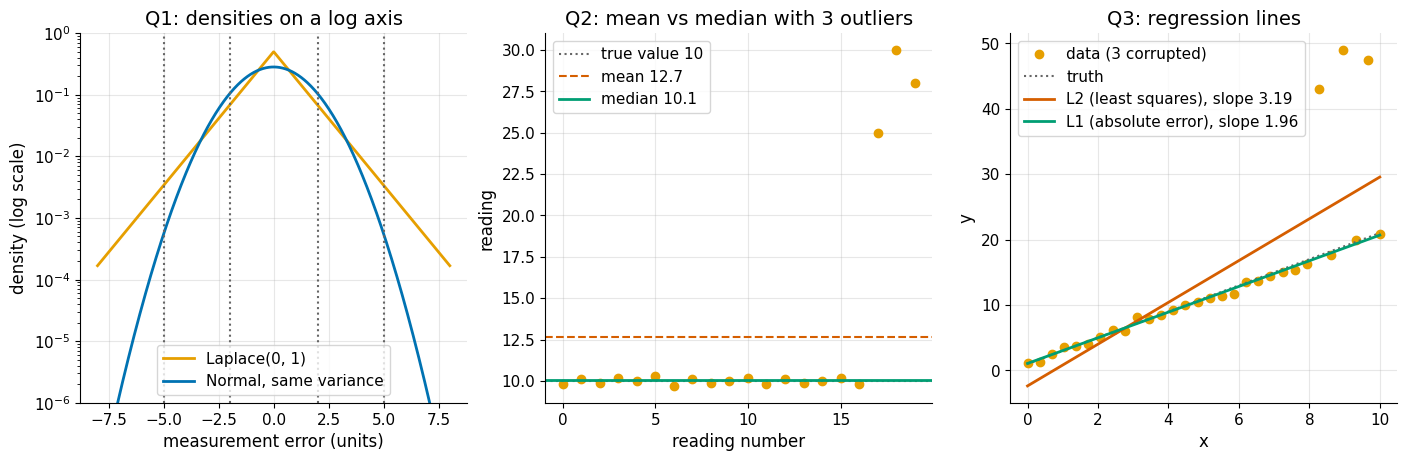

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
x_axis = np.linspace(-8, 8, 800)
axes[0].semilogy(x_axis, error_laplace.pdf(x_axis), color=COLORS[1], linewidth=2, label="Laplace(0, 1)")
axes[0].semilogy(x_axis, error_normal.pdf(x_axis), color=COLORS[0], linewidth=2, label="Normal, same variance")
for threshold in (2, 5):
    axes[0].axvline(threshold, color=NEUTRAL, linestyle=":")
    axes[0].axvline(-threshold, color=NEUTRAL, linestyle=":")
axes[0].set_ylim(1e-6, 1)
axes[0].set_title("Q1: densities on a log axis")
axes[0].set_xlabel("measurement error (units)")
axes[0].set_ylabel("density (log scale)")
axes[0].legend()

axes[1].plot(readings, "o", color=SIM)
axes[1].axhline(10, color=NEUTRAL, linestyle=":", label="true value 10")
axes[1].axhline(readings.mean(), color=HIGHLIGHT, linestyle="--", label=f"mean {readings.mean():.1f}")
axes[1].axhline(np.median(readings), color=COLORS[2], linewidth=2, label=f"median {np.median(readings):.1f}")
axes[1].set_title("Q2: mean vs median with 3 outliers")
axes[1].set_xlabel("reading number")
axes[1].set_ylabel("reading")
axes[1].legend()

axes[2].plot(x_data, y_data, "o", color=SIM, label="data (3 corrupted)")
axes[2].plot(x_data, 2 * x_data + 1, color=NEUTRAL, linestyle=":", label="truth")
axes[2].plot(x_data, slope_l2 * x_data + intercept_l2, color=HIGHLIGHT, linewidth=2, label=f"L2 (least squares), slope {slope_l2:.2f}")
axes[2].plot(x_data, slope_l1 * x_data + intercept_l1, color=COLORS[2], linewidth=2, label=f"L1 (absolute error), slope {slope_l1:.2f}")
axes[2].set_title("Q3: regression lines")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- The Laplace puts **about 17 times more probability than the Normal on errors above 5 units** (0.67 % against 0.04 %), even though both have the same variance. If errors really are Laplace-like, a Normal-based alarm threshold at 5 units would fire far too often.
- Three corrupted readings out of 20 drag the **mean to about 12.7**, while the **median stays at 10.05**. With 15 % of readings corrupted, the RMS error of the mean (2.8) is about 45 times that of the median (0.06).
- The L2 regression line is tilted by the three outliers, while the L1 line stays close to the truth (slope 2).
- **Decision:** when data may contain glitches, use **robust methods**: the median, absolute-error (L1) or Huber loss, and Laplace/heavy-tailed likelihoods. Use least squares (Normal) only when errors are well behaved.

---
### Example 2: the latent-threshold origin of the sigmoid (Logistic)

**Scenario (illustrative).** A customer buys when the latent utility $U=0.8x-2+arepsilon$ is positive, where $x$ is a marketing score (0 to 10) and $arepsilon\sim	ext{Logistic}(0,1)$. So $P(	ext{buy}\mid x)=\sigma(0.8x-2)$.

**Questions:** (a) $P(	ext{buy})$ at $x=2$ and $x=5$; (b) the score at which the probability is 50 %; (c) by what factor do the odds of buying increase per extra point of $x$?

**By hand.** (a) $x=2$: $\eta=-0.4$, $\sigma(-0.4)=1/(1+e^{0.4})=0.4013$. $x=5$: $\eta=2$, $\sigma(2)=0.8808$. (b) $0.8x-2=0\Rightarrow x=2.5$. (c) Odds multiply by $e^{0.8}=2.2255$ per point.

In [22]:
def sigmoid(z):
    return 1 / (1 + math.exp(-z))

p_buy_2_hand, p_buy_5_hand = sigmoid(0.8 * 2 - 2), sigmoid(0.8 * 5 - 2)
x_half_hand = 2 / 0.8
odds_factor_hand = math.exp(0.8)

noise = stats.logistic(0, 1)
p_buy_2_code = noise.cdf(0.8 * 2 - 2)               # P(eps > -eta) = F(eta) by symmetry
p_buy_5_code = noise.cdf(0.8 * 5 - 2)
assert np.isclose(p_buy_2_hand, p_buy_2_code) and np.isclose(p_buy_5_hand, p_buy_5_code)
odds = lambda p: p / (1 - p)
assert np.isclose(odds(sigmoid(0.8 * 3 - 2)) / odds(sigmoid(0.8 * 2 - 2)), odds_factor_hand)
print(f"P(buy | x=2) = {p_buy_2_code:.4f}, P(buy | x=5) = {p_buy_5_code:.4f}, 50 % at x = {x_half_hand}, odds factor per point = {odds_factor_hand:.4f}")

# simulate the latent model directly
x_values_sim = np.array([2.0, 5.0])
for x in x_values_sim:
    utilities = 0.8 * x - 2 + rng.logistic(0, 1, size=500_000)
    print(f"simulated P(buy | x={x:.0f}) = {np.mean(utilities > 0):.4f}")

P(buy | x=2) = 0.4013, P(buy | x=5) = 0.8808, 50 % at x = 2.5, odds factor per point = 2.2255
simulated P(buy | x=2) = 0.4017
simulated P(buy | x=5) = 0.8800


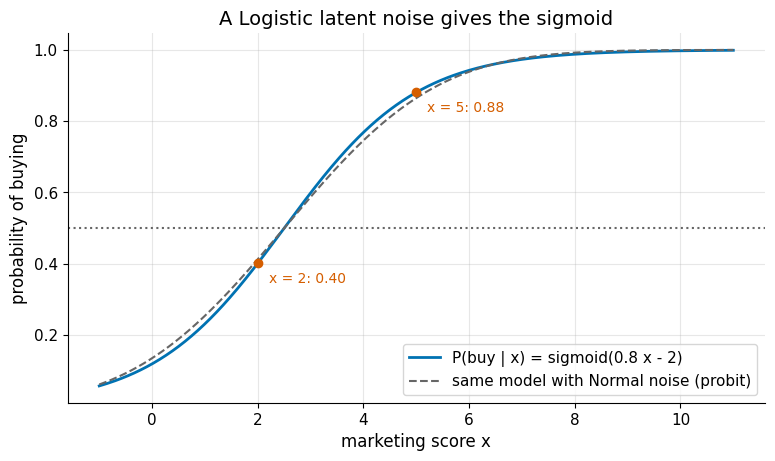

In [23]:
x_axis = np.linspace(-1, 11, 400)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x_axis, [sigmoid(0.8 * x - 2) for x in x_axis], color=MAIN, linewidth=2, label="P(buy | x) = sigmoid(0.8 x - 2)")
ax.plot(x_axis, stats.norm.cdf((0.8 * x_axis - 2) / (np.pi / np.sqrt(3))), "--", color=NEUTRAL, label="same model with Normal noise (probit)")
for x, p in [(2, p_buy_2_code), (5, p_buy_5_code)]:
    ax.plot([x], [p], "o", color=HIGHLIGHT)
    ax.annotate(f"x = {x}: {p:.2f}", (x, p), textcoords="offset points", xytext=(8, -14), color=HIGHLIGHT)
ax.axhline(0.5, color=NEUTRAL, linestyle=":")
ax.set_title("A Logistic latent noise gives the sigmoid")
ax.set_xlabel("marketing score x")
ax.set_ylabel("probability of buying")
ax.legend()
plt.show()

**Interpretation.** The sigmoid is not an arbitrary curve: it is the CDF of the Logistic noise. Each extra point of score multiplies the *odds* of buying by 2.2. A Normal-noise model (probit) gives almost the same curve, which is why logistic and probit regression usually agree; the Logistic is preferred because the log-odds are linear and easy to interpret.

---
### Example 3: yearly maximum rainfall (Gumbel) and return levels

**Scenario (illustrative).** The maximum daily rainfall in a year at a site is Gumbel with $\mu=80$ mm and $eta=20$ mm.

**Questions:** (a) the mean annual maximum; (b) $P(	ext{max}>150	ext{ mm})$ in a year, and its return period; (c) the **100-year return level**; (d) the probability of at least one year above 150 mm in the next 30 years.

**By hand.** (a) $\mu+\gammaeta=80+0.5772	imes20=91.54$ mm. (b) $z=(150-80)/20=3.5$, $P=1-\exp(-e^{-3.5})=1-\exp(-0.030197)=0.02974$; return period $1/0.02974=33.6$ years. (c) $x_{100}=\mu-eta\ln(-\ln0.99)=80-20\ln(0.010050)=80+20	imes4.600=172.0$ mm. (d) $1-(1-0.02974)^{30}=0.597$.

In [24]:
mu_rain, beta_rain = 80.0, 20.0
rain = stats.gumbel_r(loc=mu_rain, scale=beta_rain)

mean_hand = mu_rain + 0.5772156649 * beta_rain
p_over_150_hand = 1 - math.exp(-math.exp(-(150 - mu_rain) / beta_rain))
return_period_hand = 1 / p_over_150_hand
level_100_hand = mu_rain - beta_rain * math.log(-math.log(1 - 1 / 100))
p_one_in_30_hand = 1 - (1 - p_over_150_hand) ** 30

assert np.isclose(mean_hand, rain.mean())
assert np.isclose(p_over_150_hand, rain.sf(150))
assert np.isclose(level_100_hand, rain.ppf(0.99))
print(f"mean = {rain.mean():.2f} mm; P(max > 150) = {rain.sf(150):.5f} (return period {return_period_hand:.1f} years)")
print(f"100-year return level = {rain.ppf(0.99):.1f} mm; P(at least one year above 150 mm in 30 years) = {p_one_in_30_hand:.3f}")

# simulation: the yearly maximum as the max of 365 daily rainfalls (exponential-tailed days)
daily = rng.exponential(scale=beta_rain, size=(100_000, 365))
maxima = daily.max(axis=1) - beta_rain * np.log(365) + mu_rain       # shift so that it matches Gumbel(mu, beta)
print(f"max of 365 exponential days (shifted): mean {maxima.mean():.1f} (Gumbel {rain.mean():.1f}), P(> 150) = {np.mean(maxima > 150):.4f} (Gumbel {rain.sf(150):.4f})")
direct = rng.gumbel(mu_rain, beta_rain, size=1_000_000)
print(f"direct Gumbel draws: P(>150) = {np.mean(direct > 150):.4f}, 99th percentile = {np.percentile(direct, 99):.1f}")
assert abs(np.mean(direct > 150) - rain.sf(150)) < 0.001

mean = 91.54 mm; P(max > 150) = 0.02975 (return period 33.6 years)
100-year return level = 172.0 mm; P(at least one year above 150 mm in 30 years) = 0.596


max of 365 exponential days (shifted): mean 91.4 (Gumbel 91.5), P(> 150) = 0.0293 (Gumbel 0.0297)
direct Gumbel draws: P(>150) = 0.0299, 99th percentile = 171.8


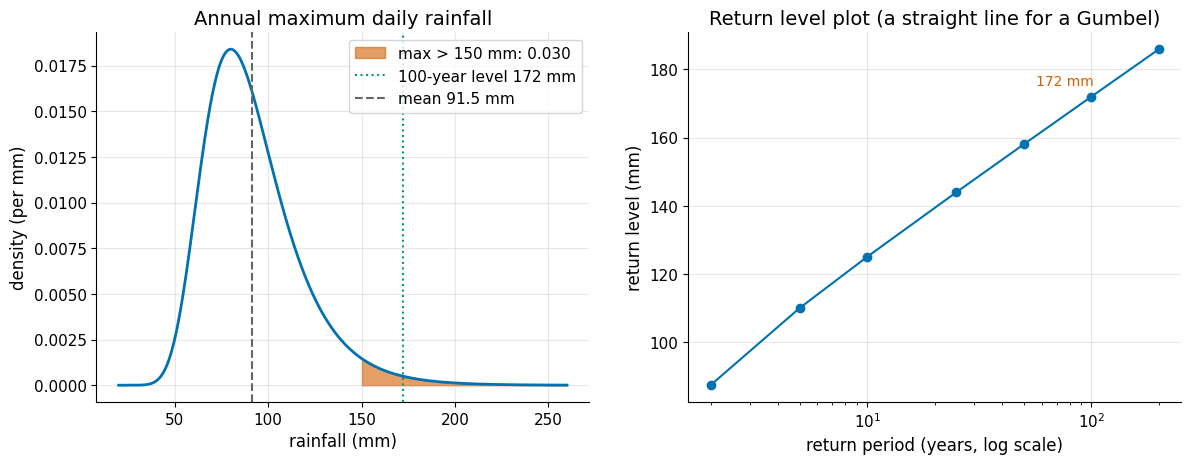

In [25]:
x_axis = np.linspace(20, 260, 600)
return_periods = np.array([2, 5, 10, 25, 50, 100, 200])
levels = rain.ppf(1 - 1 / return_periods)

fig, (ax_pdf, ax_return) = plt.subplots(1, 2, figsize=(14, 4.8))
ax_pdf.plot(x_axis, rain.pdf(x_axis), color=MAIN, linewidth=2)
over = x_axis > 150
ax_pdf.fill_between(x_axis[over], rain.pdf(x_axis[over]), color=HIGHLIGHT, alpha=0.6, label=f"max > 150 mm: {rain.sf(150):.3f}")
ax_pdf.axvline(rain.ppf(0.99), color=COLORS[2], linestyle=":", label=f"100-year level {rain.ppf(0.99):.0f} mm")
ax_pdf.axvline(rain.mean(), color=NEUTRAL, linestyle="--", label=f"mean {rain.mean():.1f} mm")
ax_pdf.set_title("Annual maximum daily rainfall")
ax_pdf.set_xlabel("rainfall (mm)")
ax_pdf.set_ylabel("density (per mm)")
ax_pdf.legend()

ax_return.semilogx(return_periods, levels, "o-", color=MAIN)
ax_return.annotate(f"{levels[5]:.0f} mm", (100, levels[5]), textcoords="offset points", xytext=(-40, 8), color=HIGHLIGHT)
ax_return.set_title("Return level plot (a straight line for a Gumbel)")
ax_return.set_xlabel("return period (years, log scale)")
ax_return.set_ylabel("return level (mm)")
plt.show()

**Interpretation.** The average annual maximum is 92 mm, but design must use the tail: a **150 mm day happens about once every 34 years** (a 60 % chance of at least one in 30 years), and the **100-year level is 172 mm**. The return-level plot is a straight line against $\ln T$ for a Gumbel, which makes extrapolation to 200 years straightforward (with the usual caution that extrapolating beyond the data is risky).

## 12. Where it is used

### Statistics
- **Robust location and regression:** median regression (quantile regression) is maximum likelihood under Laplace errors.
- **Logistic and ordinal regression:** the Logistic latent-variable model (with the Normal giving probit).
- **Extreme value analysis:** return levels, block maxima with Gumbel/GEV (hydrology, climate, finance).

### Data science
- **Differential privacy:** the **Laplace mechanism** adds Laplace noise to query results to protect individuals.
- **Forecasting with absolute error (MAE)** and median forecasts.
- **Risk and capacity:** worst-case daily load, 100-year events.

### ML and AI
- **L1 loss / MAE and L1 regularization (LASSO):** the Laplace likelihood and prior; sparsity.
- **Sigmoid and logistic regression:** the Logistic CDF is the activation of binary classifiers.
- **Gumbel-max and Gumbel-softmax:** sampling categorical choices and differentiable relaxations (VAEs with discrete latents, LLM sampling).

## 13. Common pitfalls and misconceptions

- **Parameters are not mean and SD:** Laplace SD is b times sqrt(2), Logistic SD is s times pi / sqrt(3), Gumbel SD is beta times pi / sqrt(6) and the Gumbel mean is mu + 0.5772 beta (not mu).
- **L1 minimizer is the median, not the mean:** and it can be non-unique with an even number of points.
- **`gumbel_r` vs `gumbel_l`:** `_r` is the maximum (right-skewed); `_l` the minimum (left-skewed). For maxima use `gumbel_r`.
- **Gumbel is only an approximation to maxima:** convergence can be slow, and heavy-tailed data need the Frechet law (or fit the full GEV with `stats.genextreme`).
- **Return period is not a schedule:** a 100-year event has a 1 % chance each year, and about a 26 % chance of occurring at least once in 30 years.
- **Sigmoid vs softmax:** sigmoid is for two classes (Logistic CDF), softmax for several (Gumbel-max).
- **Laplace's non-differentiable peak:** the L1 loss has a kink at 0, so use subgradient or smooth (Huber) methods in optimization.

## 14. Exercises

1. For Laplace($\mu=0$, $b=2$): find the variance, $P(|X|>4)$ and the 95th percentile.
2. Show that the median of Laplace($\mu,b$) is $\mu$ and that $P(X>\mu+t)=\tfrac12e^{-t/b}$.
3. A logistic regression has $\eta=-1+0.5x$. Find $P(Y=1)$ at $x=0$, $x=4$ and the odds ratio per unit of $x$.
4. Show that the Logistic density equals $F(x)(1-F(x))/s$ and that it is symmetric about $\mu$.
5. For the rainfall Gumbel (80, 20): what is the 50-year return level? The probability that the annual maximum is below 60 mm?
6. Using code, demonstrate that the difference of two iid Gumbel(0,1) draws follows a Logistic(0,1) distribution.
7. (Harder) Prove that $\arg\max_j(z_j+G_j)$ with iid standard Gumbel noise returns class $j$ with probability $e^{z_j}/\sum_ie^{z_i}$ for $k=2$ classes (Hint: the difference of two Gumbels is Logistic).
8. (Harder) A Laplace mechanism adds noise Laplace($0,\Delta/\varepsilon$) to a count with sensitivity $\Delta=1$. For $\varepsilon=0.5$, what is the probability that the noise exceeds 3 in absolute value? How does the answer change with $\varepsilon=2$?

Solutions are at the end.

## 15. Summary table

| Item | Laplace | Logistic | Gumbel (max) |
|---|---|---|---|
| Parameters | mu, b > 0 | mu, s > 0 | mu, beta > 0 |
| Support | all reals | all reals | all reals |
| PDF | exp(-abs(x-mu)/b) / (2b) | F(1-F)/s | exp(-z - exp(-z)) / beta |
| CDF | piecewise exponential | sigmoid((x-mu)/s) | exp(-exp(-(x-mu)/beta)) |
| Mean | mu | mu | mu + 0.5772 beta |
| Variance | 2 b^2 | pi^2 s^2 / 3 | pi^2 beta^2 / 6 |
| Excess kurtosis | 3 | 1.2 | 2.4 |
| When to use | absolute error, robust fitting, sparse priors, privacy noise | latent threshold, logistic regression | maxima, return levels, Gumbel-max sampling |
| `scipy` name | `stats.laplace(mu, b)` | `stats.logistic(mu, s)` | `stats.gumbel_r(mu, beta)` |

## Solutions

In [26]:
l1 = stats.laplace(0, 2)
print("1: var", l1.var(), " P(|X|>4) =", round(2 * l1.sf(4), 4), "= exp(-2) =", round(np.exp(-2), 4), " 95th pct =", round(l1.ppf(0.95), 4))
sig = lambda z: 1 / (1 + np.exp(-z))
print("3: P(Y=1 | x=0) =", round(sig(-1), 4), " x=4:", round(sig(1), 4), " odds ratio per unit:", round(np.exp(0.5), 4))
r = stats.gumbel_r(80, 20)
print("5: 50-year level =", round(r.ppf(1 - 1 / 50), 2), " P(max < 60) =", round(r.cdf(60), 4), "= exp(-e) =", round(np.exp(-np.e), 4))
diff = rng.gumbel(size=100_000) - rng.gumbel(size=100_000)
print("6: KS test vs Logistic(0,1): p-value =", round(stats.kstest(diff, stats.logistic.cdf).pvalue, 3))
for eps in (0.5, 2.0):
    print(f"8: epsilon = {eps}: P(|noise| > 3) = {np.exp(-3 * eps):.4f}")

1: var 8.0  P(|X|>4) = 0.1353 = exp(-2) = 0.1353  95th pct = 4.6052
3: P(Y=1 | x=0) = 0.2689  x=4: 0.7311  odds ratio per unit: 1.6487
5: 50-year level = 158.04  P(max < 60) = 0.066 = exp(-e) = 0.066
6: KS test vs Logistic(0,1): p-value = 0.8
8: epsilon = 0.5: P(|noise| > 3) = 0.2231
8: epsilon = 2.0: P(|noise| > 3) = 0.0025


**1.** Variance $2b^2=8$; $P(|X|>4)=e^{-4/2}=0.1353$; 95th percentile $=-b\ln(2\times0.05)=2\times2.303=4.605$.

**2.** By symmetry $F(\mu)=\tfrac12$; for $t>0$, $P(X>\mu+t)=\int_{\mu+t}^\infty\frac1{2b}e^{-(x-\mu)/b}dx=\tfrac12e^{-t/b}$.

**3.** $P(Y=1\mid x=0)=\sigma(-1)=0.269$; $x=4$: $\sigma(1)=0.731$; odds ratio per unit $e^{0.5}=1.649$.

**4.** $F'=e^{-z}(1+e^{-z})^{-2}=F(1-F)$ and $f(\mu+t)=f(\mu-t)$ since $e^{-t}/(1+e^{-t})^2$ is symmetric in $t$.

**5.** 50-year level $=80-20\ln(-\ln0.98)=80+20\times3.902=158.0$ mm; $P(\text{max}<60)=\exp(-e^{1})=0.0660$.

**6.** The KS test does not reject the Logistic(0,1) (large p-value): the difference of two Gumbels is Logistic.

**7.** For two classes with scores $z_1,z_2$: class 1 wins if $z_1+G_1>z_2+G_2\iff G_2-G_1<z_1-z_2$. The difference of iid standard Gumbels is Logistic(0,1), so the probability is $\sigma(z_1-z_2)=\frac{e^{z_1}}{e^{z_1}+e^{z_2}}$.

**8.** $P(|\text{noise}|>3)=e^{-3\varepsilon/\Delta}$: for $\varepsilon=0.5$, 0.223; for $\varepsilon=2$, 0.0025. Stronger privacy (smaller $\varepsilon$) means much larger noise.